
First 5 Rows:
   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0            5.1           3.5            1.4           0.2  Iris-setosa
1            4.9           3.0            1.4           0.2  Iris-setosa
2            4.7           3.2            1.3           0.2  Iris-setosa
3            4.6           3.1            1.5           0.2  Iris-setosa
4            5.0           3.6            1.4           0.2  Iris-setosa

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   SepalLengthCm  150 non-null    float64
 1   SepalWidthCm   150 non-null    float64
 2   PetalLengthCm  150 non-null    float64
 3   PetalWidthCm   150 non-null    float64
 4   Species        150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB
None

Statistical Summary:
       SepalLengthCm  SepalWidthCm

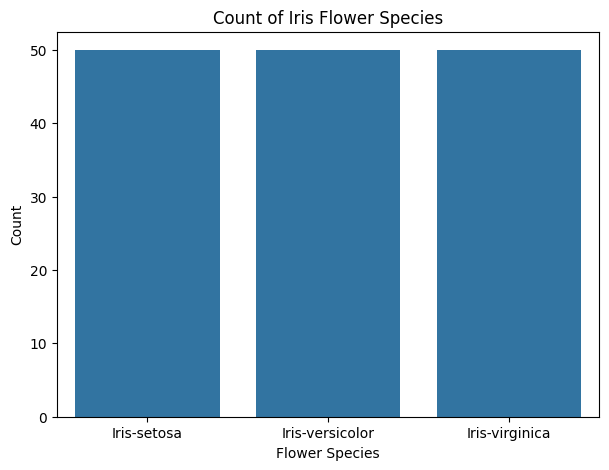

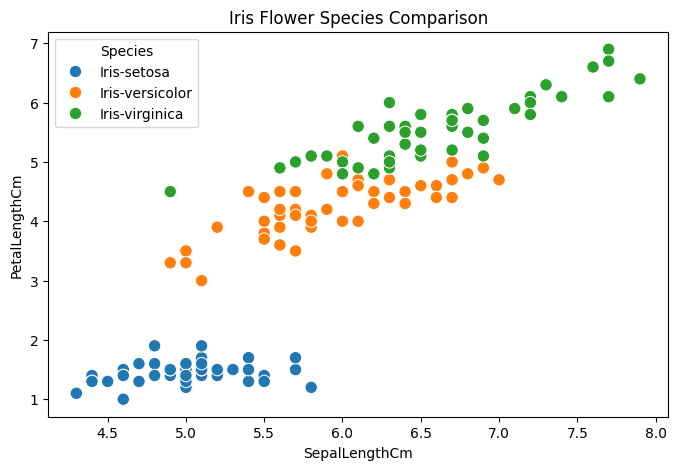

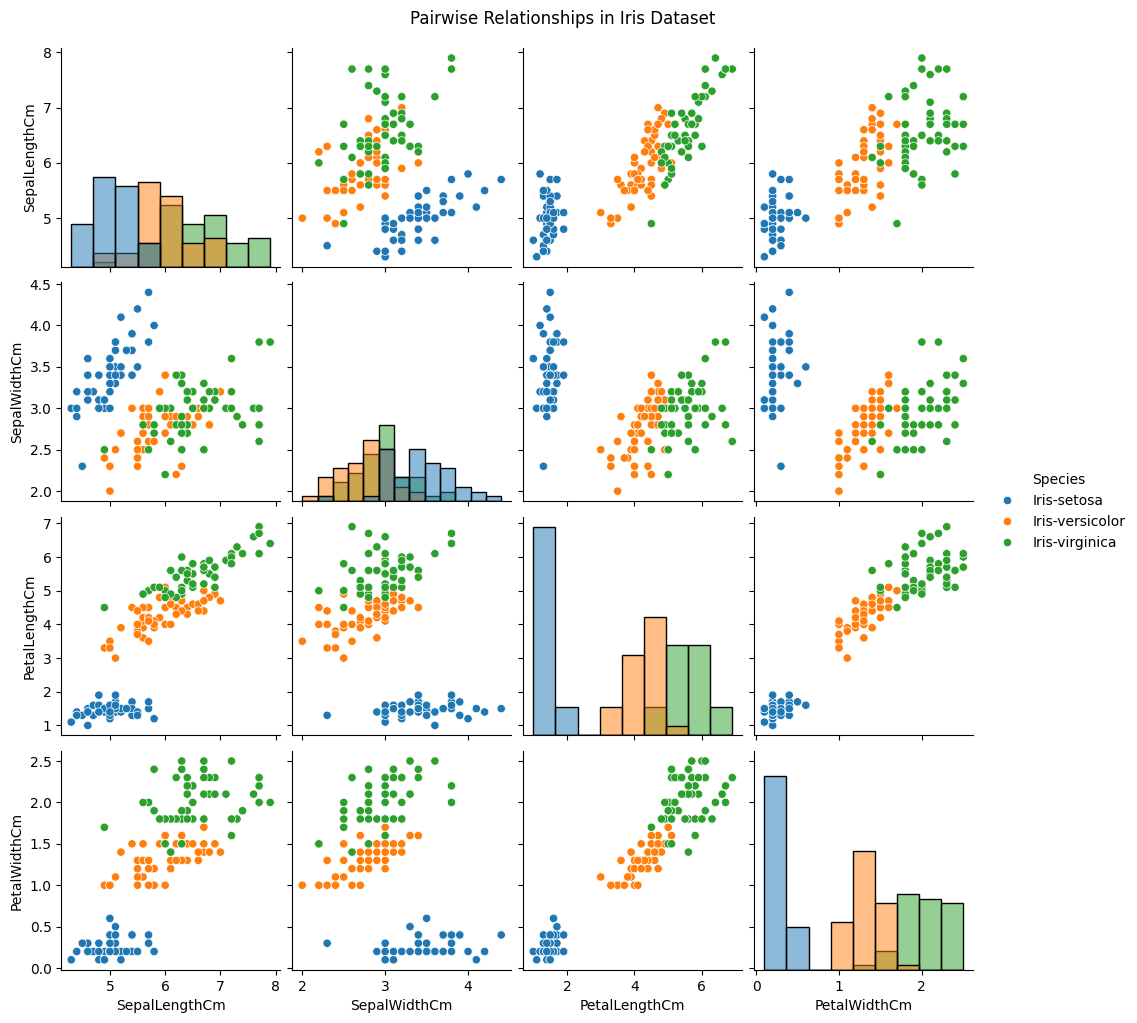


Model Accuracy: 93.33333333333333 %

Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.83      1.00      0.91        10
 Iris-virginica       1.00      0.80      0.89        10

       accuracy                           0.93        30
      macro avg       0.94      0.93      0.93        30
   weighted avg       0.94      0.93      0.93        30



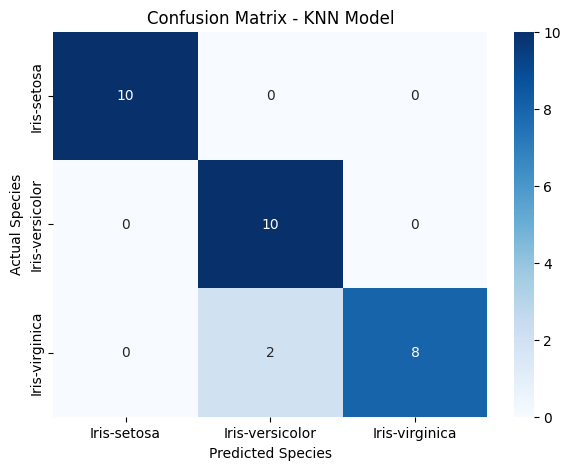


Machine Learning Model Trained Successfully!


In [ ]:

# ==========================================
#                IRIS DATASET
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

df = pd.read_csv("/content/Iris.csv")


df.columns = df.columns.str.strip()
df = df.drop(columns=["Id"], errors="ignore")

target_candidates = ["Species", "species", "Class", "class", "variety", "target"]
target = next((c for c in target_candidates if c in df.columns), df.columns[-1])

print("\nFirst 5 Rows:")
print(df.head())

print("\nDataset Information:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

df = df.dropna()

X = df.drop(columns=[target])
y = df[target]

#Visualize Dataset
# Species Count
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x=target)
plt.title("Count of Iris Flower Species")
plt.xlabel("Flower Species")
plt.ylabel("Count")
plt.show()

# Scatter Plot
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x=X.columns[0],
    y=X.columns[2],
    hue=target,
    s=80
)
plt.title("Iris Flower Species Comparison")
plt.show()

# Pair Plot
sns.pairplot(df, hue=target, diag_kind="hist")
plt.suptitle("Pairwise Relationships in Iris Dataset", y=1.02)
plt.show()

# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Train Machine Learning Model
model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

# Evaluate Model
accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy:", accuracy * 100, "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix Visualization
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("Confusion Matrix - KNN Model")
plt.show()

print("\nMachine Learning Model Trained Successfully!")
